<a href="https://colab.research.google.com/github/mtayyab03/AI-Google-Colab/blob/main/lab2_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2: K-Means Clustering from Scratch

To earn all points, you must answer all questions perfectly.

- There are **10 exercises worth 10 points each** (100 points total).
- Run the cells sequentially because later exercises depend on earlier ones.
- Implement K-Means using **NumPy**. Do **not** use `sklearn.cluster.KMeans`.
- Use Matplotlib for visualization.
- Reproduce the supplied target figures as closely as reasonably possible.
- Unless otherwise stated, use squared Euclidean distance.

You will implement Lloyd's K-Means algorithm from scratch and visualize its behavior on 2D and 3D datasets.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.18


X2 shape: (400, 2)


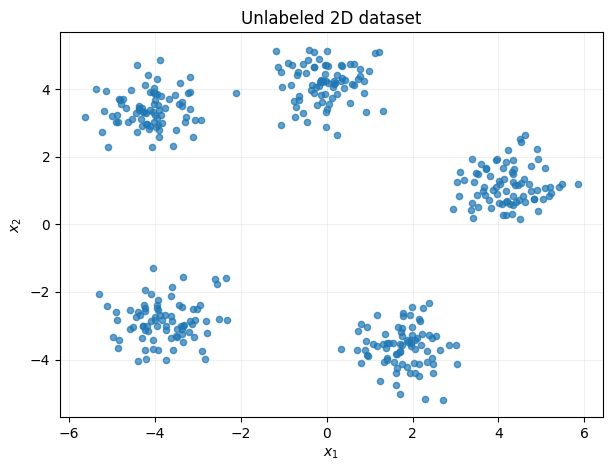

In [2]:
# Main 2D dataset used throughout the lab.
true_centers_2d = np.array([
    [-4.0,  3.5],
    [ 0.0,  4.2],
    [ 4.2,  1.3],
    [ 1.8, -3.5],
    [-3.8, -2.8],
])

X2 = np.vstack([
    rng.normal(loc=c, scale=[0.65, 0.60], size=(80, 2))
    for c in true_centers_2d
])

print("X2 shape:", X2.shape)

plt.scatter(X2[:, 0], X2[:, 1], s=20, alpha=.7)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Unlabeled 2D dataset")
plt.show()


## Exercise 1 — Pairwise squared distances [10 pts]

Implement `pairwise_squared_distances(X, centroids)` where `X` has shape `(n,d)` and `centroids` has shape `(K,d)`.

Return `D` of shape `(n,K)` with

$$
D_{ik}=\|x_i-\mu_k\|_2^2.
$$

Do not loop over data points.


In [3]:

def pairwise_squared_distances(X, centroids):

    # Calculate the difference between every point and centroid
    diff = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]

    # Square the differences and sum across features
    D = np.sum(diff ** 2, axis=2)

    return D



In [4]:
_X = np.array([[0.,0.],[1.,0.],[0.,2.]])
_C = np.array([[0.,0.],[2.,0.]])
_D = pairwise_squared_distances(_X, _C)
_expected = np.array([[0.,4.],[1.,1.],[4.,8.]])
assert _D.shape == (3,2)
assert np.allclose(_D, _expected)
assert np.all(_D >= 0)
print("Exercise 1 tests passed.")


Exercise 1 tests passed.


## Exercise 2 — Assignment step [10 pts]

For fixed centroids, K-Means assigns each point to its nearest centroid:

$$
c_i=\arg\min_k \|x_i-\mu_k\|_2^2.
$$

Implement `assign_clusters(X, centroids)` using Exercise 1. Return a one-dimensional integer array of length `n`.


In [5]:

def assign_clusters(X, centroids):

    # Calculate distances using Exercise 1
    distances = pairwise_squared_distances(X, centroids)

    # Find the nearest centroid for each point
    labels = np.argmin(distances, axis=1)

    return labels


In [6]:
_X = np.array([[0.,0.],[0.2,0.1],[5.,5.],[4.8,5.2]])
_C = np.array([[0.,0.],[5.,5.]])
labels = assign_clusters(_X, _C)
assert labels.shape == (4,)
assert np.array_equal(labels, np.array([0,0,1,1]))
print("Exercise 2 tests passed.")


Exercise 2 tests passed.


## Exercise 3 — Centroid update [10 pts]

Implement `update_centroids(X, labels, K, rng=None)` using

$$
\mu_k=\frac{1}{|C_k|}\sum_{i\in C_k}x_i.
$$

If a cluster is empty, reinitialize that centroid to a randomly selected observation from `X`.


In [7]:

def update_centroids(X, labels, K, rng=None):

    if rng is None:
        rng = np.random.default_rng()

    # Get number of features
    n_features = X.shape[1]

    # Create an empty array for new centroids
    centroids = np.zeros((K, n_features))

    # Calculate centroid for every cluster
    for k in range(K):

        # Select points belonging to cluster k
        cluster_points = X[labels == k]

        if len(cluster_points) > 0:

            # Calculate the mean of the points
            centroids[k] = np.mean(cluster_points, axis=0)

        else:

            # Handle an empty cluster
            random_index = rng.integers(len(X))
            centroids[k] = X[random_index]

    return centroids



In [8]:
_X = np.array([[0.,0.],[2.,0.],[8.,8.],[10.,8.]])
_labels = np.array([0,0,1,1])
C = update_centroids(_X, _labels, K=2, rng=np.random.default_rng(0))
assert C.shape == (2,2)
assert np.allclose(C, np.array([[1.,0.],[9.,8.]]))
print("Exercise 3 tests passed.")


Exercise 3 tests passed.


## Exercise 4 — K-Means objective [10 pts]

Implement the mean within-cluster squared distance

$$
J=\frac1n\sum_{i=1}^n\|x_i-\mu_{c_i}\|_2^2.
$$

Your function should be called `kmeans_objective(X, labels, centroids)`.

Then verify that updating the centroids while holding assignments fixed does not increase the objective.


In [9]:

def kmeans_objective(X, labels, centroids):

    # Select the assigned centroid for every point
    assigned_centroids = centroids[labels]

    # Calculate squared distances
    squared_distances = np.sum(
        (X - assigned_centroids) ** 2,
        axis=1
    )

    # Calculate average squared distance
    J = np.mean(squared_distances)

    return J



In [10]:
rr = np.random.default_rng(12)
initial_centroids = X2[rr.choice(len(X2), 5, replace=False)].copy()
labels0 = assign_clusters(X2, initial_centroids)
J0 = kmeans_objective(X2, labels0, initial_centroids)

centroids1 = update_centroids(X2, labels0, K=5, rng=rr)
J1 = kmeans_objective(X2, labels0, centroids1)

print("before:", J0)
print("after: ", J1)
assert J1 <= J0 + 1e-12
print("Exercise 4 tests passed.")


before: 6.810610066104444
after:  3.8064784691228923
Exercise 4 tests passed.


## Exercise 5 — Lloyd's K-Means algorithm [10 pts]

Implement

```python
kmeans(X, K, max_iter=100, tol=1e-6, seed=0)
```

It must:

1. initialize `K` distinct data points as centroids;
2. alternate assignment and update steps;
3. record the objective after each full iteration;
4. stop when the centroid movement is below `tol`;
5. return

```python
labels, centroids, objective_history, centroid_history
```

where `centroid_history` includes the initial centroids.


In [11]:

def kmeans(X, K, max_iter=100, tol=1e-6, seed=0):

    # Create random number generator
    rng = np.random.default_rng(seed)

    # Step 1: Initialize K distinct centroids
    indices = rng.choice(len(X), size=K, replace=False)
    centroids = X[indices].copy()

    # Store objective values
    objective_history = []

    # Store centroid positions
    centroid_history = [centroids.copy()]

    # Repeat K-Means iterations
    for iteration in range(max_iter):

        # Step 2: Assign points to nearest centroids
        labels = assign_clusters(X, centroids)

        # Step 3: Calculate new centroids
        new_centroids = update_centroids(
            X, labels, K, rng
        )

        # Calculate objective using updated centroids
        J = kmeans_objective(X, labels, new_centroids)

        objective_history.append(J)

        # Store updated centroids
        centroid_history.append(new_centroids.copy())

        # Calculate centroid movement
        movement = np.linalg.norm(
            new_centroids - centroids
        )

        # Update centroids
        centroids = new_centroids

        # Stop if movement is very small
        if movement < tol:
            break

    # Final cluster assignment
    labels = assign_clusters(X, centroids)

    return (
        labels,
        centroids,
        objective_history,
        centroid_history
    )


In [12]:
labels5, centroids5, hist5, cent_hist5 = kmeans(X2, K=5, seed=3)
assert labels5.shape == (len(X2),)
assert centroids5.shape == (5,2)
assert len(cent_hist5) == len(hist5) + 1
assert np.all(np.diff(hist5) <= 1e-9)
print("iterations:", len(hist5))
print("final objective:", hist5[-1])
print("Exercise 5 tests passed.")


iterations: 11
final objective: 3.806792835832261
Exercise 5 tests passed.


## Exercise 6 — Final 2D clustering plot [10 pts]

Run your implementation with `K=5, seed=3`.

Produce a scatter plot with:

- one color per discovered cluster;
- final centroids shown with large `X` markers;
- axis labels and a title.

Reproduce the target:

![Target 2D clustering](images/exercise06_target_2d.png)


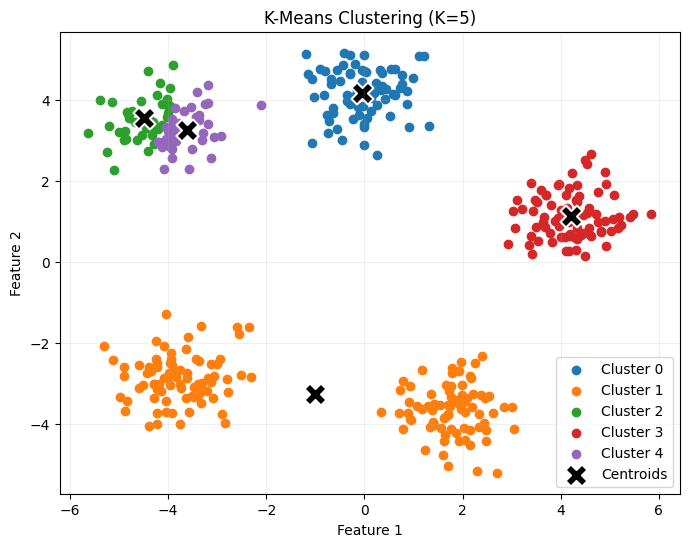

In [14]:

# Run K-Means with K=5
labels5, centroids5, hist5, cent_hist5 = kmeans(
    X2, K=5, seed=3
)

# Create scatter plot
plt.figure(figsize=(8, 6))

# Plot each cluster
for k in range(5):

    points = X2[labels5 == k]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        label=f"Cluster {k}"
    )

# Plot final centroids
plt.scatter(
    centroids5[:, 0],
    centroids5[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolors="white",
    linewidths=1.5,
    label="Centroids"
)

# Add labels and title
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering (K=5)")

plt.legend()
plt.show()


## Exercise 7 — Visualize the optimization trajectory [10 pts]

Using `centroid_history`, create several side-by-side panels showing K-Means from initialization toward convergence.

At each selected iteration:

1. assign points to the centroids from that iteration;
2. color the points by those assignments;
3. show the current centroids with large `X` markers.

Reproduce the target:

![Target history](images/exercise07_target_history.png)


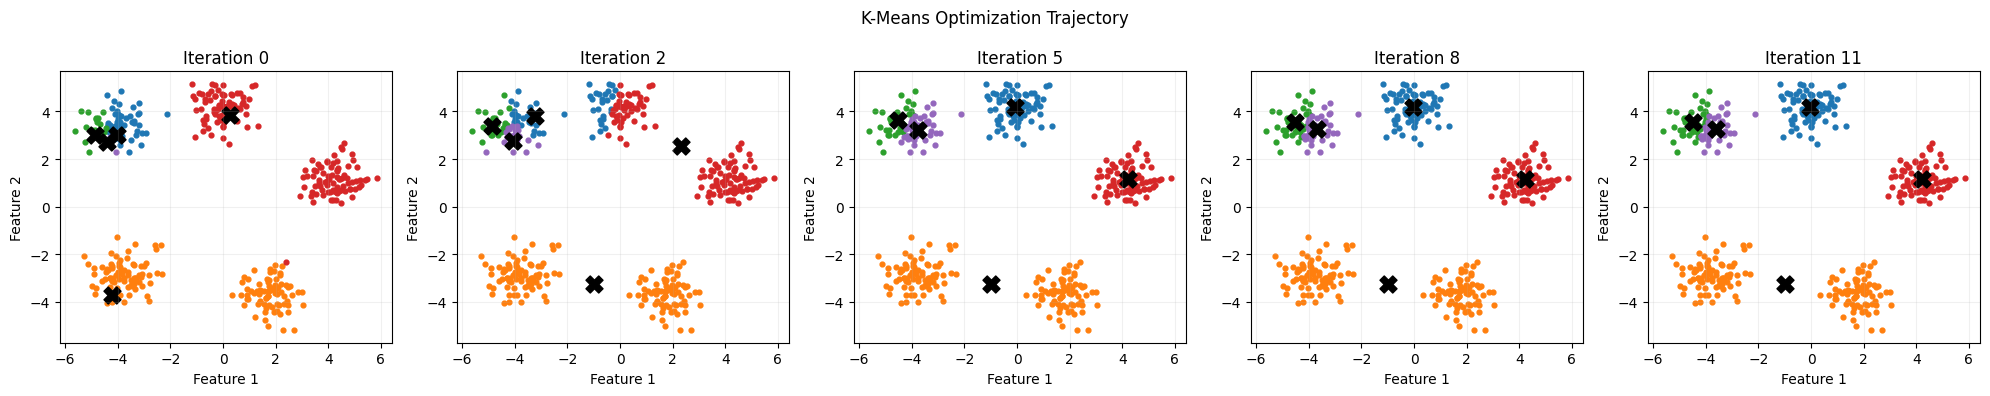

In [15]:

# Select iterations to visualize
num_panels = 5

selected = np.linspace(
    0,
    len(cent_hist5) - 1,
    num_panels,
    dtype=int
)

# Create side-by-side plots
fig, axes = plt.subplots(
    1, num_panels,
    figsize=(20, 4)
)

for ax, iteration in zip(axes, selected):

    # Get centroids at selected iteration
    current_centroids = cent_hist5[iteration]

    # Assign points using current centroids
    current_labels = assign_clusters(
        X2, current_centroids
    )

    # Plot clusters
    for k in range(5):

        points = X2[current_labels == k]

        ax.scatter(
            points[:, 0],
            points[:, 1],
            s=12
        )

    # Plot current centroids
    ax.scatter(
        current_centroids[:, 0],
        current_centroids[:, 1],
        marker="X",
        s=150,
        color="black"
    )

    ax.set_title(f"Iteration {iteration}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.suptitle("K-Means Optimization Trajectory")
plt.tight_layout()
plt.show()



## Exercise 8 — K-Means++ and random restarts [10 pts]

### Part A
Implement `kmeans_plus_plus_init(X, K, seed=0)`:

1. choose the first centroid uniformly from the data;
2. compute each point's squared distance to its nearest chosen centroid;
3. choose the next centroid with probability proportional to that squared distance;
4. repeat until `K` centroids are selected.

### Part B
Implement `kmeans_restarts(X, K, n_init=10, seed=0)` that runs K-Means several times and returns the result with the smallest final objective.

Compare one random run against the best of ten restarts.


In [16]:

def kmeans_plus_plus_init(X, K, seed=0):

    rng = np.random.default_rng(seed)

    # Select first centroid randomly
    first_index = rng.integers(len(X))

    centroids = [X[first_index].copy()]

    # Select remaining centroids
    for _ in range(1, K):

        # Calculate distances to selected centroids
        distances = pairwise_squared_distances(
            X, np.array(centroids)
        )

        # Find nearest centroid distance
        min_distances = np.min(distances, axis=1)

        # Calculate selection probabilities
        total = np.sum(min_distances)

        if total == 0:
            index = rng.integers(len(X))
        else:
            probabilities = min_distances / total

            index = rng.choice(
                len(X),
                p=probabilities
            )

        centroids.append(X[index].copy())

    return np.array(centroids)


def kmeans_restarts(X, K, n_init=10, seed=0):

    best_result = None
    best_objective = float("inf")

    # Run K-Means multiple times
    for i in range(n_init):

        # Use a different seed for every run
        current_seed = seed + i

        result = kmeans(
            X,
            K,
            seed=current_seed
        )

        # Get final objective
        current_objective = result[2][-1]

        # Keep the best result
        if current_objective < best_objective:

            best_objective = current_objective
            best_result = result

    return best_result


In [17]:
C_pp = kmeans_plus_plus_init(X2, K=5, seed=0)
assert C_pp.shape == (5,2)

one_run = kmeans(X2, K=5, seed=0)
best_run = kmeans_restarts(X2, K=5, n_init=10, seed=0)

print("single-run objective:", one_run[2][-1])
print("best-of-10 objective:", best_run[2][-1])

assert best_run[2][-1] <= one_run[2][-1] + 1e-12
print("Exercise 8 tests passed.")


single-run objective: 0.6895774241643747
best-of-10 objective: 0.6895774241643747
Exercise 8 tests passed.


## Exercise 9 — K-Means in 3D [10 pts]

Generate the 3D dataset below, cluster it into `K=4` groups using your own implementation, and create a 3D scatter plot.

Show the learned centroids using large `X` markers.

Target:

![Target 3D clustering](images/exercise09_target_3d.png)


In [18]:
rng3 = np.random.default_rng(9)

true_centers_3d = np.array([
    [-4.0, -3.0, -2.0],
    [ 3.5, -2.5,  2.0],
    [-1.0,  4.0,  3.0],
    [ 4.0,  3.5, -2.5],
])

X3 = np.vstack([
    rng3.normal(loc=c, scale=.7, size=(90,3))
    for c in true_centers_3d
])

print("X3 shape:", X3.shape)


X3 shape: (360, 3)


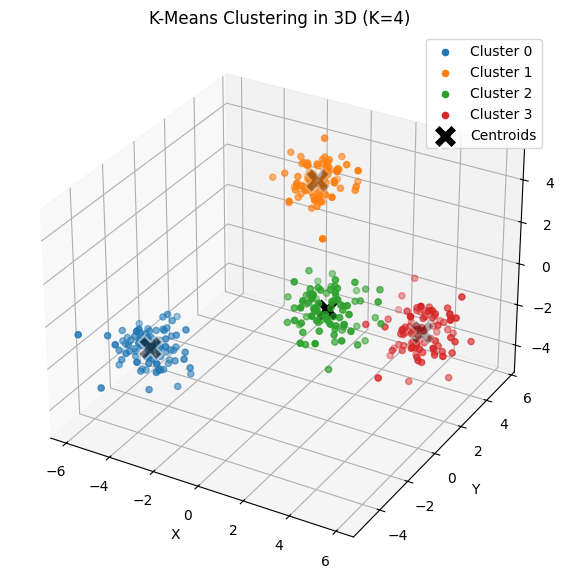

In [19]:

# Run K-Means on 3D dataset
labels3, centroids3, hist3, cent_hist3 = kmeans(
    X3,
    K=4,
    seed=3
)

# Create 3D figure
fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

# Plot each cluster
for k in range(4):

    points = X3[labels3 == k]

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        label=f"Cluster {k}"
    )

# Plot centroids
ax.scatter(
    centroids3[:, 0],
    centroids3[:, 1],
    centroids3[:, 2],
    marker="X",
    s=300,
    color="black",
    edgecolors="white",
    linewidths=1.5,
    label="Centroids"
)

# Add axis labels
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.set_title("K-Means Clustering in 3D (K=4)")

ax.legend()

plt.show()


## Exercise 10 — Choosing \(K\): the elbow method [10 pts]

For each \(K=1,\dots,9\), run `kmeans_restarts` using several restarts and record the smallest final objective.

Plot objective versus \(K\).

Target:

![Target elbow curve](images/exercise10_target_elbow.png)

Answer:

1. Where is the strongest elbow?
2. Why must the optimal K-Means objective be non-increasing as \(K\) grows?
3. Why not choose the largest possible \(K\)?
4. What value of \(K\) would you choose here?


K = 1, Objective = 21.1288
K = 2, Objective = 11.5445
K = 3, Objective = 5.2727
K = 4, Objective = 2.3893
K = 5, Objective = 0.6896
K = 6, Objective = 0.6304
K = 7, Objective = 0.5830
K = 8, Objective = 0.5422
K = 9, Objective = 0.5009


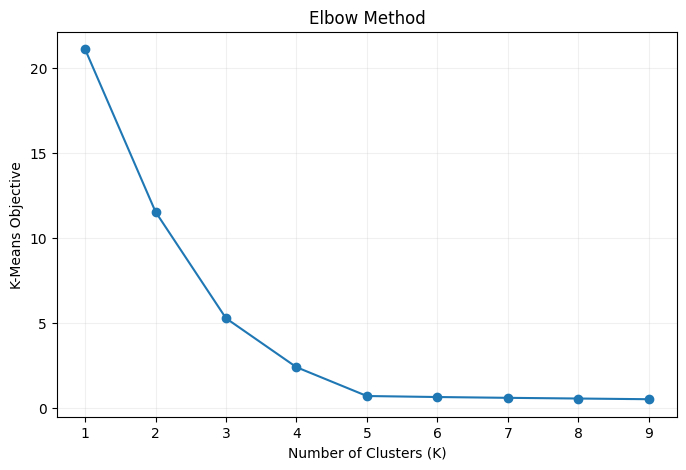

In [20]:

# Store objective values for different K
K_values = range(1, 10)

objectives = []

# Test K from 1 to 9
for K in K_values:

    # Run multiple restarts
    best_result = kmeans_restarts(
        X2,
        K,
        n_init=10,
        seed=0
    )

    # Get smallest final objective
    best_objective = best_result[2][-1]

    objectives.append(best_objective)

    print(
        f"K = {K}, Objective = {best_objective:.4f}"
    )

# Plot elbow curve
plt.figure(figsize=(8, 5))

plt.plot(
    list(K_values),
    objectives,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("K-Means Objective")

plt.title("Elbow Method")

plt.xticks(list(K_values))

plt.show()
